In [10]:
import sklearn.datasets as datasets
import numpy as np
import matplotlib.pyplot as plt

(1000, 2)


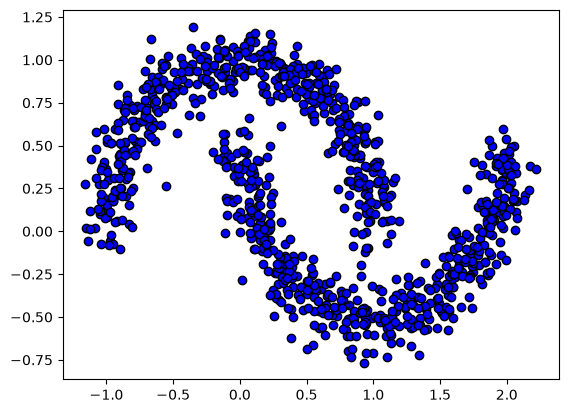

In [13]:
data, _ = datasets.make_moons(n_samples=1000, noise=0.1)

print(data.shape) 
plt.scatter(data[:, 0], data[:, 1], c='blue', edgecolor='k')
plt.show()


In [32]:
class Two_D_histogram:
    def __init__(self, x_bins, y_bins, uniform_sample):
        self.x_bins = x_bins
        self.y_bins = y_bins
        self.histogram = [[0 for _ in range(y_bins)] for _ in range(x_bins)]
        self.uniform_sample = uniform_sample
        self.data = data

    def fit(self):
       

        self.x_edges = np.linspace(np.min(data[:, 0]), np.max(data[:, 0]), self.x_bins + 1)
        self.y_edges = np.linspace(np.min(data[:, 1]), np.max(data[:, 1]), self.y_bins + 1)

        self.histogram, _, _ = np.histogram2d(data[:, 0], data[:, 1], bins=[self.x_edges, self.y_edges])


        self.bin_areas = np.diff(self.x_edges)[:, None] * np.diff(self.y_edges)[None, :]

        self.histogram_probability_density = self.histogram / (np.sum(self.histogram) * self.bin_areas)

        self.cdf = np.cumsum(self.histogram_probability_density.flatten())

        self.cdf[-1] = 1.0

        return self

    def sample(self, n_samples):
        uniform_samples = np.random.default_rng().uniform(0, 1, n_samples)
        bin_indices = np.searchsorted(self.cdf, uniform_samples)
        x_indices, y_indices = np.unravel_index(bin_indices, self.histogram.shape)
        x_samples = np.random.uniform(self.x_edges[x_indices], self.x_edges[x_indices + 1])
        y_samples = np.random.uniform(self.y_edges[y_indices], self.y_edges[y_indices + 1])
        return np.column_stack((x_samples, y_samples))  

    def score_samples(self, data):
        x_indices = np.searchsorted(self.x_edges, data[:,0], side='right') - 1
        y_indices = np.searchsorted(self.y_edges, data[:,1], side='right') - 1

        inside = (x_indices >= 0) & (x_indices < self.x_bins) & (y_indices >= 0) & (y_indices < self.y_bins)
        densitiy = (self.histogram_probability_density[x_indices[inside], y_indices[inside]])
        return densitiy




    def plot_histogram(self):
        plt.imshow(self.histogram.T, origin='lower', extent=[self.x_edges[0], self.x_edges[-1], self.y_edges[0], self.y_edges[-1]], cmap='viridis')
        plt.colorbar(label='Count')
        plt.xlabel('X')
        plt.ylabel('Y')
        plt.title('2D Histogram')
        plt.show()





    

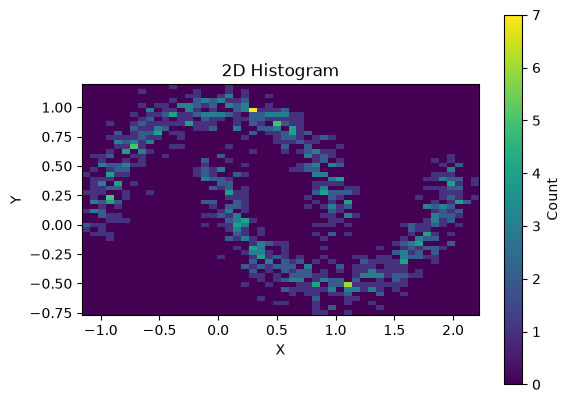

[[-1.11532407 -0.05189145]
 [-1.15115086 -0.05172567]
 [-1.10923194 -0.01619364]
 [-1.1256607  -0.04888293]
 [-1.14102034 -0.01057765]
 [-1.12386049 -0.05235389]
 [-1.11623718 -0.04776145]
 [-1.10455274 -0.05028698]
 [-1.1447794  -0.01382012]
 [-1.15444651 -0.01501703]]
[1.50991804 0.37747951 0.75495902 0.37747951 0.75495902 0.37747951
 1.13243853 0.37747951 1.13243853 0.37747951]


In [36]:
Two_D_hist = Two_D_histogram(x_bins=50, y_bins=50, uniform_sample=True)
Two_D_hist.fit()

Two_D_hist.plot_histogram()

print(Two_D_hist.sample(10))
print(Two_D_hist.score_samples(data[:10]))
